# Mom or Dad? (simple version)

**Goal:** look at a father, a mother and their child, and say which parent the child looks more like, using PCA.

**The plan, one step at a time:**
1. Load the TSKinFace faces.
2. Clean each face: grayscale, cut away the background, equalise brightness.
3. Split families into train and test.
4. Build a test: is a child closer to its own parents than to other couples?
5. Baseline PCA, then improve it one idea at a time and re-run the test after each idea.
6. Region map: which parts of the face come from which parent.
7. The final "Mom or Dad" verdict, made fair for sons and daughters.
8. Save everything the app needs.

In [1]:
import os, glob
import numpy as np
import cv2
from matplotlib import pyplot as plt
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

DATA = 'TSKinFace_Data/TSKinFace_cropped/'     # folder that holds FMSD, FMS, FMD

## 1. Load the faces
TSKinFace has three folders:
* **FMSD**: father, mother, son, daughter
* **FMS**: father, mother, son
* **FMD**: father, mother, daughter

Files are named like `FMSD-12-F.jpg` (family 12, father). Every face is already cropped to 64×64 with the eyes in the same place.

We store the data as **trios** (father, mother, child). A FMSD family gives two trios, one for the son and one for the daughter.

In [2]:
def read(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)     # OpenCV loads BGR; we want RGB

fathers, mothers, children, is_son, family = [], [], [], [], []
for folder in ['FMSD', 'FMS', 'FMD']:
    for f_path in sorted(glob.glob(DATA + folder + '/*-F.jpg')):
        fam = f_path[:-6]                                    # '.../FMSD-12'  (drop '-F.jpg')
        for child in ['S', 'D']:
            c_path = fam + '-' + child + '.jpg'
            if os.path.exists(c_path):
                fathers.append(read(fam + '-F.jpg'))
                mothers.append(read(fam + '-M.jpg'))
                children.append(read(c_path))
                is_son.append(child == 'S')
                family.append(os.path.basename(fam))

fathers, mothers, children = np.array(fathers), np.array(mothers), np.array(children)
is_son, family = np.array(is_son), np.array(family)
print(fathers.shape, 'trios from', len(set(family)), 'families')

(1015, 64, 64, 3) trios from 787 families


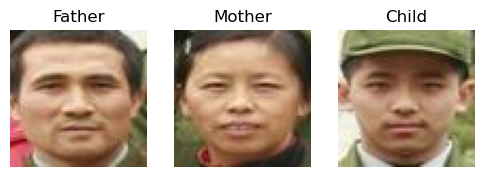

In [3]:
plt.figure(figsize=(6, 2))
for i, (img, name) in enumerate(zip([fathers[2], mothers[2], children[2]], ['Father', 'Mother', 'Child'])):
    plt.subplot(1, 3, i + 1); plt.imshow(img); plt.title(name); plt.axis('off')
plt.show()

## 2. Clean each face
* **Grayscale**: colour mostly tells us about the camera, not the genes (we prove this in step 5).
* **Face mask**: an ellipse that keeps the face and throws away background, hair and clothes. Every family member in TSKinFace was cut out of the **same family photo**, so the background is a giveaway that has nothing to do with resemblance.
* **Histogram equalisation**: spreads the brightness over the full 0–255 range, so a dark photo and a bright photo look alike.

Each face then becomes one row of 64 × 64 = 4096 numbers.

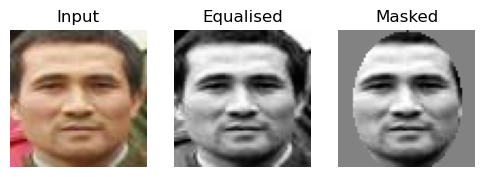

In [4]:
yy, xx = np.mgrid[0:64, 0:64] / 64
MASK = ((xx - 0.5) / 0.40) ** 2 + ((yy - 0.52) / 0.52) ** 2 <= 1      # True inside the ellipse

def prep(images, use_mask=True):
    rows = []
    for img in images:
        g = cv2.equalizeHist(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)).astype(float)
        if use_mask:
            g[~MASK] = 128                     # background -> plain grey
        rows.append(g.reshape(-1))
    return np.array(rows)

plt.figure(figsize=(6, 2))
plt.subplot(1, 3, 1); plt.imshow(fathers[2]); plt.title('Input'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(prep(fathers[2:3], use_mask=False)[0].reshape(64, 64), cmap='gray'); plt.title('Equalised'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(prep(fathers[2:3])[0].reshape(64, 64), cmap='gray'); plt.title('Masked'); plt.axis('off')
plt.show()

## 3. Train / test split by family
We split **families**, not images. If a son were in train and his sister in test, the model would have already seen the parents, which is cheating. 80% of families go to train and 20% to test.

In [5]:
fams = np.unique(family)
train_fams, test_fams = train_test_split(fams, test_size=0.2, random_state=42)
train = np.isin(family, train_fams)
test = np.isin(family, test_fams)
print('train trios:', train.sum(), ' test trios:', test.sum())

train trios: 806  test trios: 209


## 4. How we measure resemblance
**Main test (parents):** for each test child, compare it with its own parents' average face and with every *other* test family's parents. Accuracy is the fraction of other families that look *less* like the child than its own parents do. 50% means guessing; 100% means perfect.

**Control test (spouses):** run the same test on husband vs wife. They are **not** related, but they are in the same photo. If spouses "match", the model is matching the *photo* (lighting, camera, colour), not the family. So:

> **good model = high parents score, spouse score close to 50%**

The **margin** (parents − spouse) is the part we can believe is real resemblance.

In [6]:
def accuracy(S, fam):
    """S[i, j] = similarity between person i and candidate j. The right answer is on the diagonal.
    Candidates from the same family (e.g. the same parents for a sister) are skipped."""
    scores = []
    for i in range(len(S)):
        others = fam != fam[i]
        scores.append(np.mean(S[i, others] < S[i, i]))
    return np.mean(scores)

def run_tests(Z_father, Z_mother, Z_child, fam, similarity):
    """Z_* are the faces of the test trios after projecting into some face space."""
    parents = (Z_father + Z_mother) / 2
    _, one = np.unique(fam, return_index=True)          # each couple only once for the spouse test
    p = accuracy(similarity(Z_child, parents), fam)
    s = accuracy(similarity(Z_father[one], Z_mother[one]), fam[one])
    return p, s

def euclid_sim(A, B):
    return -euclidean_distances(A, B)                   # smaller distance = more similar

results = []
def report(name, p, s):
    results.append((name, p, s))
    print(f'{name:38s} parents {p:.1%}   spouse {s:.1%}   margin {p - s:+.1%}')

## 5. Baseline, then one improvement at a time

### Control: no face at all
First, a model that only sees the **background**: the average and spread of the colours in a 6-pixel border around the crop. There is no face in it at all.

In [7]:
ring = np.ones((64, 64), bool); ring[6:-6, 6:-6] = False
def border_colour(images):
    return np.array([np.concatenate([img[ring].mean(0), img[ring].std(0)]) for img in images])

train_border = np.concatenate([border_colour(x[train]) for x in (fathers, mothers, children)])
mu, sd = train_border.mean(0), train_border.std(0)                  # scale each feature like the training set
B = [(border_colour(x[test]) - mu) / sd for x in (fathers, mothers, children)]
report('CONTROL: background only, no face', *run_tests(*B, family[test], euclid_sim))

CONTROL: background only, no face      parents 69.9%   spouse 72.0%   margin -2.1%


The background alone does almost as well as the baseline below. **The photo leaks the answer.** Every step that follows is judged on the margin, not only on the parents score.

### Baseline: plain PCA (the first version of the project)
PCA finds the main "directions" in which faces differ (the **eigenfaces**). Each face becomes a short list of numbers: how much of each eigenface it contains. `PCA(0.95)` keeps enough eigenfaces to explain 95% of the variation.

In [8]:
X_train = np.concatenate([prep(x[train], use_mask=False) for x in (fathers, mothers, children)])
pca = PCA(0.95).fit(X_train)
Z = [pca.transform(prep(x[test], use_mask=False)) for x in (fathers, mothers, children)]
report('Baseline PCA', *run_tests(*Z, family[test], euclid_sim))

Baseline PCA                           parents 75.2%   spouse 68.0%   margin +7.2%


### Improvement 1: face mask
The same PCA, but the background is removed before PCA sees the face.

+ face mask                            parents 77.6%   spouse 68.7%   margin +8.9%


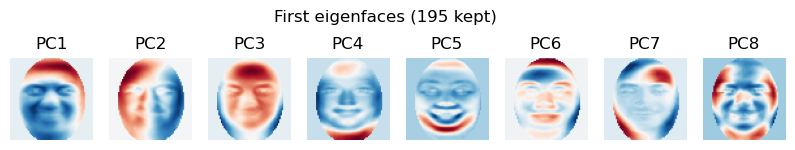

In [9]:
X_train = np.concatenate([prep(x[train]) for x in (fathers, mothers, children)])
pca = PCA(0.95).fit(X_train)
Z = [pca.transform(prep(x[test])) for x in (fathers, mothers, children)]
report('+ face mask', *run_tests(*Z, family[test], euclid_sim))

plt.figure(figsize=(10, 1.6))
for i in range(8):
    plt.subplot(1, 8, i + 1); plt.imshow(pca.components_[i].reshape(64, 64), cmap='RdBu_r'); plt.title(f'PC{i+1}'); plt.axis('off')
plt.suptitle(f'First eigenfaces ({pca.n_components_} kept)', y=1.05); plt.show()

### Improvement 2: whitening + cosine similarity
The first few eigenfaces are mostly **lighting and pose**. They have huge variance, so they dominate a normal (Euclidean) distance.
* **Whitening** divides every PCA number by its standard deviation, so every eigenface gets an equal vote. In sklearn this is just `PCA(0.95, whiten=True)`.
* **Cosine similarity** compares the *direction* of two faces in PCA space and ignores the overall length (contrast).

In [10]:
pca = PCA(0.95, whiten=True).fit(X_train)
Z = [pca.transform(prep(x[test])) for x in (fathers, mothers, children)]
report('+ whitening + cosine', *run_tests(*Z, family[test], cosine_similarity))

+ whitening + cosine                   parents 79.5%   spouse 65.1%   margin +14.4%


### Improvement 3: remove the "photo" directions
This is the key idea. Husband and wife are **not** related, so anything their faces have in common in PCA space must come from the shared **photo** (lighting direction, contrast, blur, camera).

PCA finds those shared directions for us: we take the **cross-covariance** between husbands' and wives' PCA numbers and keep its top eigenvectors. These are the directions along which spouses move together.

To delete them we use a **projection matrix** `P = I − Q Qᵀ`, where the columns of Q are the directions (made orthonormal). Multiplying a face by P removes its part along those directions and leaves everything else unchanged. We delete the top 20.

In [11]:
def removal_matrix(directions):
    Q, _ = np.linalg.qr(np.column_stack(directions))     # orthonormal version of the directions
    return np.eye(len(Q)) - Q @ Q.T

Zf, Zm = pca.transform(prep(fathers[train])), pca.transform(prep(mothers[train]))
_, one = np.unique(family[train], return_index=True)     # each training couple once
A = Zf[one] - Zf[one].mean(0)
Bm = Zm[one] - Zm[one].mean(0)
shared = (A.T @ Bm + Bm.T @ A) / (2 * len(A))             # symmetric husband-wife cross-covariance
values, vectors = np.linalg.eigh(shared)                  # eigenvalues come out smallest first
photo_dirs = vectors[:, ::-1][:, :20]                     # top 20 shared directions

P = removal_matrix(list(photo_dirs.T))
Z = [pca.transform(prep(x[test])) @ P for x in (fathers, mothers, children)]
report('+ remove photo directions (final)', *run_tests(*Z, family[test], cosine_similarity))

+ remove photo directions (final)      parents 74.8%   spouse 57.5%   margin +17.3%


**What about sex and age?** A son could look "like dad" just for being male. We tested removing an average-male-minus-female direction and an adult-minus-child direction too, using 5-fold cross-validation over all families. Accuracy didn't change (72.4% with vs 72.7% without), and the verdict's fairness is handled better in step 7, so we leave it out to keep things simple.

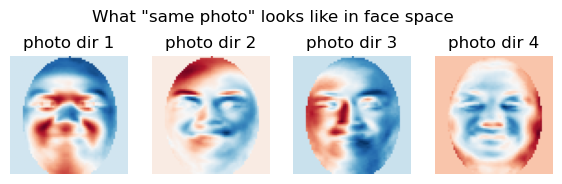

In [12]:
plt.figure(figsize=(7, 1.8))
for i in range(4):
    img = (pca.components_.T * np.sqrt(pca.explained_variance_)) @ photo_dirs[:, i]   # back to pixels
    plt.subplot(1, 4, i + 1); plt.imshow(img.reshape(64, 64), cmap='RdBu_r'); plt.title(f'photo dir {i+1}'); plt.axis('off')
plt.suptitle('What "same photo" looks like in face space', y=1.08); plt.show()

### Why not colour?
Colour (skin tone) sounds like a great inherited feature. Let's test PCA on colour only, using the a* and b* channels of the LAB colour space (lightness removed).

In [13]:
def colour(images):
    return np.array([cv2.cvtColor(cv2.resize(i, (32, 32)), cv2.COLOR_RGB2LAB)[:, :, 1:].reshape(-1) for i in images], dtype=float)
pca_col = PCA(0.95, whiten=True).fit(np.concatenate([colour(x[train]) for x in (fathers, mothers, children)]))
Z = [pca_col.transform(colour(x[test])) for x in (fathers, mothers, children)]
report('Colour PCA (looks great...)', *run_tests(*Z, family[test], cosine_similarity))

Colour PCA (looks great...)            parents 82.4%   spouse 74.0%   margin +8.4%


The parents score is the highest so far, **but spouses also match far above 50%**, so the margin is worse than the grayscale model's. Much of the colour is the photo's colour cast, not skin tone, which is why we stay with grayscale.

### Summary of step 5
One train/test split moves these numbers by ±2–3 points (about 200 test children). The pattern is what matters: each cleaning step lowers the spouse (photo) score faster than the parents score, so the margin grows.

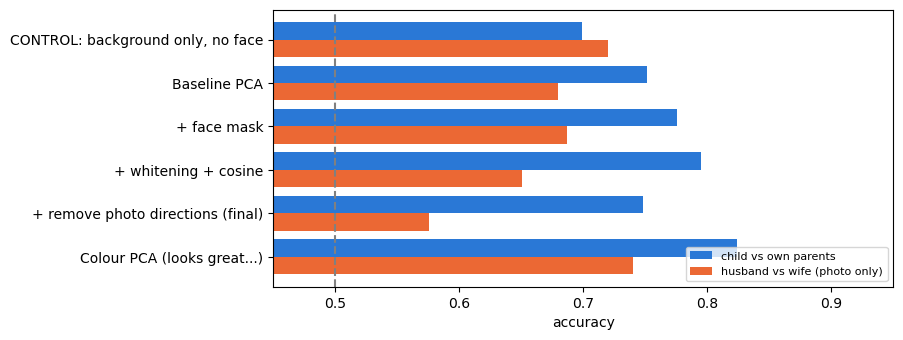

In [14]:
names = [r[0] for r in results]; par = [r[1] for r in results]; spo = [r[2] for r in results]
y = np.arange(len(names))[::-1]
plt.figure(figsize=(8, 3.6))
plt.barh(y + 0.2, par, 0.4, color='#2a78d6', label='child vs own parents')
plt.barh(y - 0.2, spo, 0.4, color='#eb6834', label='husband vs wife (photo only)')
plt.axvline(0.5, color='grey', ls='--'); plt.yticks(y, names); plt.xlim(0.45, 0.95)
plt.xlabel('accuracy'); plt.legend(loc='lower right', fontsize=8); plt.show()

## 6. Region map: which features come from which parent?
We repeat the same pipeline on six small patches (forehead, eyes, nose, mouth, chin), cut out of the cleaned faces from step 2. Each patch gets its own small PCA, with its top 5 photo directions removed (small patches have fewer dimensions, so fewer directions to remove).

To avoid copying code six times, the steps from section 5 go into one function, `fit_space`. It returns the two things needed to use a face space: the PCA and the removal matrix P.

In [15]:
REGIONS = {'Forehead': (4, 20, 12, 52), 'Left eye': (20, 31, 8, 30), 'Right eye': (20, 31, 34, 56),
           'Nose': (28, 40, 22, 42), 'Mouth': (38, 50, 16, 48), 'Chin': (50, 62, 16, 48)}   # (top, bottom, left, right)

def fit_space(Xf, Xm, Xc, fam, n_photo):
    """Section 5 in one function: whitened PCA + remove the top photo directions."""
    pca = PCA(0.95, whiten=True).fit(np.concatenate([Xf, Xm, Xc]))
    Zf, Zm = pca.transform(Xf), pca.transform(Xm)
    _, one = np.unique(fam, return_index=True)                 # each couple once
    A, B = Zf[one] - Zf[one].mean(0), Zm[one] - Zm[one].mean(0)
    _, vectors = np.linalg.eigh((A.T @ B + B.T @ A) / (2 * len(A)))
    P = removal_matrix(list(vectors[:, ::-1][:, :n_photo].T))
    return pca, P

def project(X, pca, P):
    return pca.transform(X) @ P

def region(X, box):
    """Cut one patch out of cleaned faces (rows of 4096 numbers)."""
    top, bottom, left, right = box
    return X.reshape(-1, 64, 64)[:, top:bottom, left:right].reshape(len(X), -1)

X_all = [prep(x) for x in (fathers, mothers, children)]       # cleaned faces: father, mother, child

for name, box in REGIONS.items():
    tr = [region(x[train], box) for x in X_all]
    pca_r, P_r = fit_space(*tr, family[train], n_photo=5)
    Z = [project(region(x[test], box), pca_r, P_r) for x in X_all]
    p, s = run_tests(*Z, family[test], cosine_similarity)
    print(f'{name:9s} parents {p:.1%}   spouse {s:.1%}')

Forehead  parents 59.0%   spouse 51.2%
Left eye  parents 70.3%   spouse 56.5%
Right eye parents 70.6%   spouse 57.8%
Nose      parents 63.1%   spouse 52.4%
Mouth     parents 61.2%   spouse 55.0%
Chin      parents 59.7%   spouse 55.7%


The **eyes** are where children resemble parents most (about 70%), then the nose. Every region's parents score is above its spouse score, so the map shows real resemblance and not only the photo. Small patches are noisy, though, so treat the map as a guide, not proof.

## 7. The verdict: Mom or Dad?
For one child:

> **g = cosine(child, father) − cosine(child, mother)**     (positive = more like dad)

**Problem:** sons are judged "like dad" more often than daughters, partly just because they are boys. **Fix:** compare the child's g with the g of other children **of the same sex** in the training set. The verdict becomes "more like dad than 70% of sons", which is fair to both.

Both parents come from the same photo, so the photo affects them equally and cancels out of g.

**Checking the bias needs more test children than one split gives.** With about 100 sons in the test set, the "% judged like dad" number moves by ±5–8 points just from which families land in test. So we repeat the split 5 times (**5-fold by family**), and every child is tested once by a model that never saw its family.

In [16]:
from sklearn.model_selection import KFold

def cos_rows(A, B):
    """cosine similarity of row i of A with row i of B"""
    return np.sum(A * B, axis=1) / (np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1))

def lean(Zf, Zm, Zc):
    return cos_rows(Zc, Zf) - cos_rows(Zc, Zm)

def percentile(g, son, g_ref, son_ref):
    """Share of same-sex reference children with a smaller g, i.e. less dad-like than this child."""
    return np.array([np.mean(g_ref[son_ref == s] < v) for v, s in zip(g, son)])

X_plain = [prep(x, use_mask=False) for x in (fathers, mothers, children)]   # baseline faces

base_dad = np.zeros(len(family), bool)
raw_dad = np.zeros(len(family), bool)
pct = np.zeros(len(family))
for tr_idx, te_idx in KFold(5, shuffle=True, random_state=42).split(fams):
    tr, te = np.isin(family, fams[tr_idx]), np.isin(family, fams[te_idx])
    # cleaned face space, fitted on the training families of this fold
    pca_h, P_h = fit_space(*[x[tr] for x in X_all], family[tr], n_photo=20)
    g_tr = lean(*[project(x[tr], pca_h, P_h) for x in X_all])
    g_te = lean(*[project(x[te], pca_h, P_h) for x in X_all])
    raw_dad[te] = g_te > 0
    pct[te] = percentile(g_te, is_son[te], g_tr, is_son[tr])
    # baseline for comparison: plain PCA, whichever parent is closer
    pca_b = PCA(0.95).fit(np.concatenate([x[tr] for x in X_plain]))
    bf, bm, bc = [pca_b.transform(x[te]) for x in X_plain]
    base_dad[te] = np.linalg.norm(bc - bf, axis=1) < np.linalg.norm(bc - bm, axis=1)

s = is_son
for name, dad in [('Baseline PCA', base_dad), ('Cleaned, raw g > 0', raw_dad), ('Cleaned, calibrated', pct > 0.5)]:
    print(f'{name:22s}  sons -> dad {dad[s].mean():.0%}   daughters -> dad {dad[~s].mean():.0%}')

Baseline PCA            sons -> dad 51%   daughters -> dad 41%
Cleaned, raw g > 0      sons -> dad 51%   daughters -> dad 45%
Cleaned, calibrated     sons -> dad 49%   daughters -> dad 49%


Ideally both numbers are near 50% and close to each other. The baseline favours the same-sex parent (sons 51% vs daughters 41%). Calibration brings the two groups together, because every child is compared only with children of its own sex.

## 8. Save the model for the app
Every step in the face space is **linear**:

> whitened PCA:  z = (x − mean) · components.T / √variance,     then  z · P

So the whole pipeline is a single matrix `W = components.T / √variance · P`, and the app only needs `(x − mean) @ W`. This means the app needs NumPy but not scikit-learn.

For the app we refit on **all** families, since more data gives a better model, and store:
* the whole-face space and the six region spaces (mean + W)
* the g values of all sons and daughters, for the calibrated verdict
* child-vs-own-parents and child-vs-stranger similarities, for the "do they look related?" gauge

In [17]:
def to_matrix(pca, P):
    return pca.mean_, (pca.components_.T / np.sqrt(pca.explained_variance_)) @ P

model = {}
pca_h, P_h = fit_space(*X_all, family, n_photo=20)
model['face_mean'], model['face_W'] = to_matrix(pca_h, P_h)
Zf, Zm, Zc = [project(x, pca_h, P_h) for x in X_all]
g_all = lean(Zf, Zm, Zc)
model['g_son'], model['g_daughter'] = g_all[is_son], g_all[~is_son]

own = cosine_similarity(Zc, (Zf + Zm) / 2)
model['sim_own'] = np.diag(own)                                   # child vs own parents
model['sim_stranger'] = own[family[:, None] != family[None, :]][::50]   # child vs other couples (a sample)

for i, (name, box) in enumerate(REGIONS.items()):
    Xr = [region(x, box) for x in X_all]
    pca_r, P_r = fit_space(*Xr, family, n_photo=5)
    model[f'r{i}_mean'], model[f'r{i}_W'] = to_matrix(pca_r, P_r)
    g = lean(*[project(x, pca_r, P_r) for x in Xr])
    model[f'r{i}_g_son'], model[f'r{i}_g_daughter'] = g[is_son], g[~is_son]

model['region_names'] = np.array(list(REGIONS)); model['region_boxes'] = np.array(list(REGIONS.values()))

np.savez_compressed('model.npz', **{k: (v.astype(np.float32) if v.dtype == float else v) for k, v in model.items()})
print('saved model.npz', round(os.path.getsize('model.npz') / 1e6, 1), 'MB')

saved model.npz 2.7 MB
